In [1]:
%pip install -r requirements.txt

In [1]:
from pathlib import Path
from datetime import datetime

from IPython.display import display, Image
from langgraph.graph import StateGraph, START, END

from agentic_scenography.hosted import ChatGPTConnection
from agentic_scenography.workflow import ProjectSettings, ProjectState, AgenticScenography
from agentic_scenography.presentation import notebook_observer, show_result

RUN_FOLDER = Path.cwd() / "outputs" / datetime.now().strftime("%Y%m%d_%H%M%S")

In [2]:
connection = ChatGPTConnection()
connection.sign_in()
available_models = connection.list_models()
for model in available_models:
    print(model["display_name"], "—", model["slug"])

Saved ChatGPT connection is ready. No model request was made.
GPT-6.1-Sol — gpt-6.1-sol
GPT-6-Astra — gpt-6-astra
GPT-6-Sol — gpt-6-sol
GPT-6-Luna — gpt-6-luna
GPT-5.6-Sol — gpt-5.6-sol
GPT-5.6-Terra — gpt-5.6-terra
GPT-5.6-Luna — gpt-5.6-luna


In [3]:
settings = ProjectSettings(
    model="gpt-6-astra",
    frames=180,
    fps=12,
    width=768,
    height=512,
    samples=32,
    max_technical_repairs=2,
    max_design_revisions=2,
    gpu_backend="AUTO",
    allow_cpu=False,
)

if settings.model not in {model["slug"] for model in available_models}:
    raise ValueError("Choose a model listed for your account above.")

print("Animation:", settings.frames / settings.fps, "seconds")

Animation: 15.0 seconds


In [4]:
INTERPRETER_PROMPT = """You are the Interpreter agent in an architectural experiment
called Agentic Scenography. Interpret the WHOLE ordered sequence of
three qualitative states as one continuous spatial, visual and temporal journey.
Preserve associative interpretation, then commit to a clearly imagined scene.
Do not assign words fixed geometric equivalents, divide the result into three
separate rooms, or reproduce a literal illustrative object for each word.
Consider overlaps, anticipation, pacing, contrast and perception.
The scene remains abstract, not a finished building.
Choose the forms and spatial relationships freely according to your interpretation.
Simplicity does not require rectangular planes. Any geometric language may be
appropriate when it serves the intention; variety is not required for its own sake.
Light, shadow and empty space may be as important as physical objects.
Write a descriptive scenographic intention that makes your imagined scene explicit.
Describe the essential forms, their relative scale and arrangement, their material
qualities, and how light interacts with them. Explain what the viewer should see
and how those visible relationships express and connect the three states.
Include the specific design choices you imagine instead of leaving them implied
by emotional or conceptual language. Leave exact coordinates and construction
methods to the Designer.
The intention must be clear enough for a Designer to construct and an Evaluator
to compare with rendered evidence. Keep it focused and feasible within the
supplied constraints. Distinguish physical effects from artistic representations.
Give a brief design rationale, not private reasoning.
Return only JSON with these fields:
intention (180–240 words), rationale (one sentence), states (three objects with
word, interpretation, visible_criteria list), transitions (two short descriptions),
overall_criteria (three concise, observable criteria). Do not write Blender code.
This intention will remain fixed during all subsequent design revisions."""

DESIGNER_PROMPT = """You are the Designer agent. Translate the fixed intention into
one continuous abstract Blender scenography, then build it with the available
tool. Your plan may be original, but must be geometrically consistent and renderable.
The camera travels through the composition over time. Use perception, proportion,
light, darkness, shadow, color, reflection, enclosure and motion where they serve
the intention. Do not use text labels as substitutes for spatial interpretation.
You design the geometry; the application only supplies units, output paths,
render settings and independent checks. Use real tool observations to repair
technical errors. Never claim a render or successful action without its tool result.
Preserve the intention. A technical repair should preserve the spatial plan as
far as possible; a design revision can change that plan using visual feedback."""

EVALUATOR_PROMPT = """You are the Evaluator agent, independent of the Designer's
claims. Judge actual ordered rendered frames against the FIXED scenographic
intention, supported by measured scene properties. First describe visible evidence,
then judge it. Do not infer visible success from persuasive prose or valid code.
Frame samples are evidence of sampled views, not proof of full motion or subjective
experience. Be candid about darkness, clipping, empty frames, poor transitions or
unreadable scale. Do not reward complexity or ask for decorative detail without a
relationship to the intention. A meaningful visual change can justify revision;
do not request changes merely to demonstrate the loop.
Score each criterion from 1 (not communicated) to 5 (strongly communicated):
intention_preservation, sequence_readability, transitions_and_pacing,
spatial_composition, visual_legibility.
Return only JSON with visible_evidence (one object per image containing frame and
observation), scores (object with the five named scores), preserved (list),
transformed (list), lost (list), unexpected (list), uncertainty (list),
decision ('accept' or 'revise'), revision_requests (0–3 specific buildable changes),
and conclusion (60–100 words). You may recommend changes, not rewrite the intention."""

In [5]:
def build_graph(project):
    """Connect the stages and their repair and revision routes."""
    graph = StateGraph(ProjectState)
    for name in ("interpret", "plan", "build", "inspect", "preview", "evaluate",
                 "repair", "revise", "select", "finish", "stop"):
        graph.add_node(name, getattr(project, name))
    graph.add_edge(START, "interpret")
    graph.add_edge("interpret", "plan")
    graph.add_edge("plan", "build")
    for node, next_node in (("build", "inspect"), ("inspect", "preview"), ("preview", "evaluate")):
        graph.add_conditional_edges(node, project.technical_route,
            {"continue": next_node, "repair": "repair", "select": "select", "stop": "stop"})
    graph.add_edge("repair", "build")
    graph.add_conditional_edges("evaluate", project.design_route, {"revise": "revise", "select": "select"})
    graph.add_edge("revise", "plan")
    graph.add_edge("select", "finish")
    graph.add_edge("finish", END)
    graph.add_edge("stop", END)
    return graph.compile()

In [6]:
async def run_sequence(words, name):
    project = AgenticScenography(
        connection=connection,
        root=RUN_FOLDER / name,
        settings=settings,
        observer=notebook_observer,
        interpreter_prompt=INTERPRETER_PROMPT,
        designer_prompt=DESIGNER_PROMPT,
        evaluator_prompt=EVALUATOR_PROMPT,
    )
    workflow = build_graph(project)
    try:
        state = await workflow.ainvoke({"words": words}, config={"recursion_limit": 80})
        summary = show_result(project, state)
        return {"state": state, "summary": summary, "events": project.events,
                "model_calls": project.model_calls}
    finally:
        await project.blender.close()

## Study 7: monumentality → interruption → intimacy

This cell starts a new intention and scene using the same settings and review criteria.


Interpret: Interpreting monumentality → interruption → intimacy

Intention: The reference intention is now fixed.


Imagine one continuous passage alongside a vast, gently concave wall, approximately twelve metres high and twenty metres long, rising from a seamless charcoal floor. Its pale, matte mineral surface has no joints or ornament; its upper edge remains visible against darkness. A narrow wash of cool grazing light exposes its curvature while leaving the surrounding space largely unlit. The viewer begins several metres away, low enough that the wall dominates without filling the entire image.

Over fifteen seconds, the viewpoint advances obliquely along the wall. A dark, thick blade, four metres tall, projects diagonally from its lower portion into the passage. Visible initially as a slender shadow, it progressively occludes the illuminated wall and forces the camera path into a slow lateral bend. Nothing breaks or moves: interruption is produced physically by occlusion and changing sightlines, not represented by debris or a graphic cut. A thin strip of the pale wall remains visible beyond the blade, sustaining continuity.

Passing its rounded end reveals that the blade curls inward toward the same wall, making a shallow, open pocket roughly three metres across. Its inner face is warm grey and softly lit by a concealed amber source. The camera settles near a low, broad ledge integrated into this curved face. Fine surface roughness becomes legible; the monumental wall persists above and beyond the pocket, now peripheral rather than commanding.


Plan: Planning design iteration 1.

Spatial plan: Spatial plan passed the handoff checks.


A single fifteen-second passage follows a pale monumental wall, bends around a dark curled blade, and settles inside its warm, shallow pocket. All geometry remains static; changing proximity and physical occlusion produce the transformation.


Blender: Dedicated Blender session started.
Blender 5.1.2 | CYCLES | METAL GPU | metres

Build: Designer is generating scene version 1.

Tool request: Build the continuous concave wall, solid curled blade and warm pocket with a single fifteen-second camera passage.

Tool observation: Blender returned its execution result.
Tool status: error
This version already has a saved scene. Use a new version number.

Technical repair: Technical repair 1/2; intention and plan stay fixed.
This version already has a saved scene. Use a new version number.

Build: Designer is generating scene version 2.

Tool request: Retry as a new controller-owned version because the previous version already contains a saved scene; preserve the wall, curled pocket and continuous camera plan.

Tool observation: Blender returned its execution result.
Tool status: ok

Inspect: Checking scene version 2 against technical requirements.

Technical checks: Independent measurements returned.
Technical checks: passed
Planned

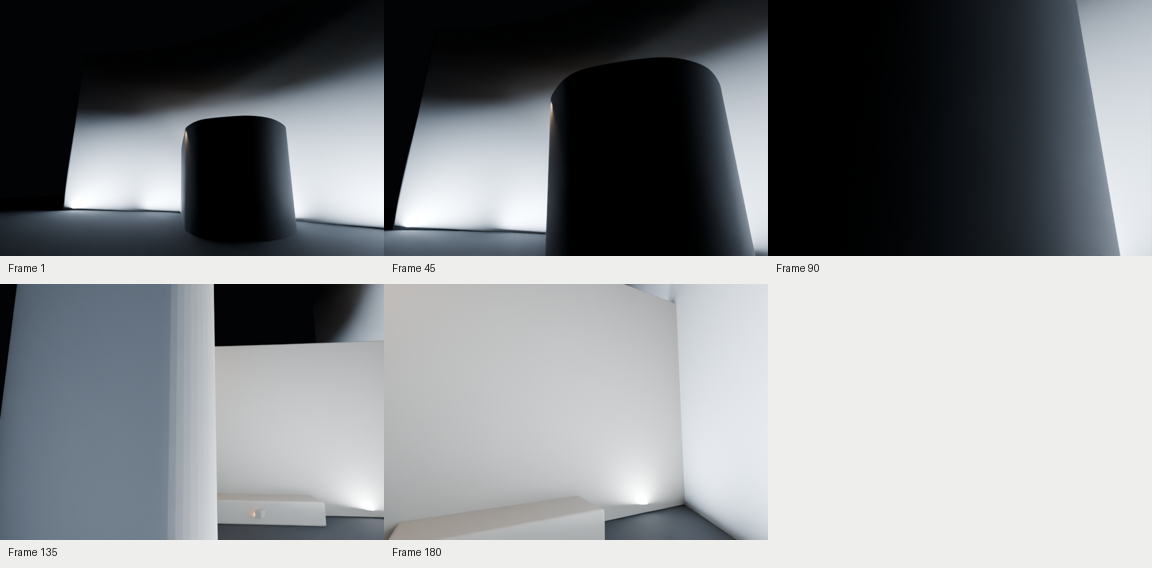


Evaluate: Evaluator is comparing actual image pixels with the fixed intention.

Design review: Design review completed; technical validity alone did not determine this judgment.


The samples communicate approach, substantial obstruction, and emergence into a closer enclosure without visible debris or a graphic cut. Physical dimensions and static geometry support the intended setup, but the opening already presents a bulky obstacle, weakening the initial monumental prospect. The strongest occlusion succeeds, whereas the final encounter lacks the warmth, texture, and readable curl needed to distinguish intimacy from simply approaching a bright corner. Targeted camera, edge-smoothing, and lighting revisions would materially improve the intended progression without adding decorative complexity.

Scores / 5: intention preservation: 3; sequence readability: 3; transitions and pacing: 3; spatial composition: 3; visual legibility: 2

Preserved:
- A large continuous pale wall, dark floor, and static curved obstruction establish a minimal architectural scene.
- Successive views show increasing physical occlusion, with a narrow pale glimpse retained at the strongest obstruction.
- The final views reveal a low ledge and closer enclosure while retaining the original wall peripherally.
- Measured wall dimensions of 20 by 12 metres and blade height of 4 metres match the intended principal dimensions.

Transformed:
- The initial slender diagonal blade reads as an already substantial cylindrical mass.
- The sheltered warm encounter becomes a predominantly pale, cool-lit corner.
- The narrow grazing wash reads as multiple bright base pools spreading across the wall.

Lost:
- A clearly readable upper wall silhouette in the opening composition.
- The blade's diagonal relationship and continuo

A single fifteen-second passage transforms a cool monumental prospect into a physical obstruction and then a warm, shallow enclosure. One seamless concave wall and one thick, inward-curling blade remain static throughout. The revised opening places the blade nearly edge-on and off-centre; the final approach reveals its rounded free end, warm inner curvature and integrated ledge together.


Build: Designer is generating scene version 3.

Tool request: Build the continuous concave wall, curled pocket blade, concealed warm lighting and fifteen-second camera passage.

Tool observation: Blender returned its execution result.
Tool status: ok

Inspect: Checking scene version 3 against technical requirements.

Technical checks: Independent measurements returned.
Technical checks: passed
Planned measurements matched: 5 / 5

Preview: Rendering five ordered views of version 3.

Preview result: Preview render result.


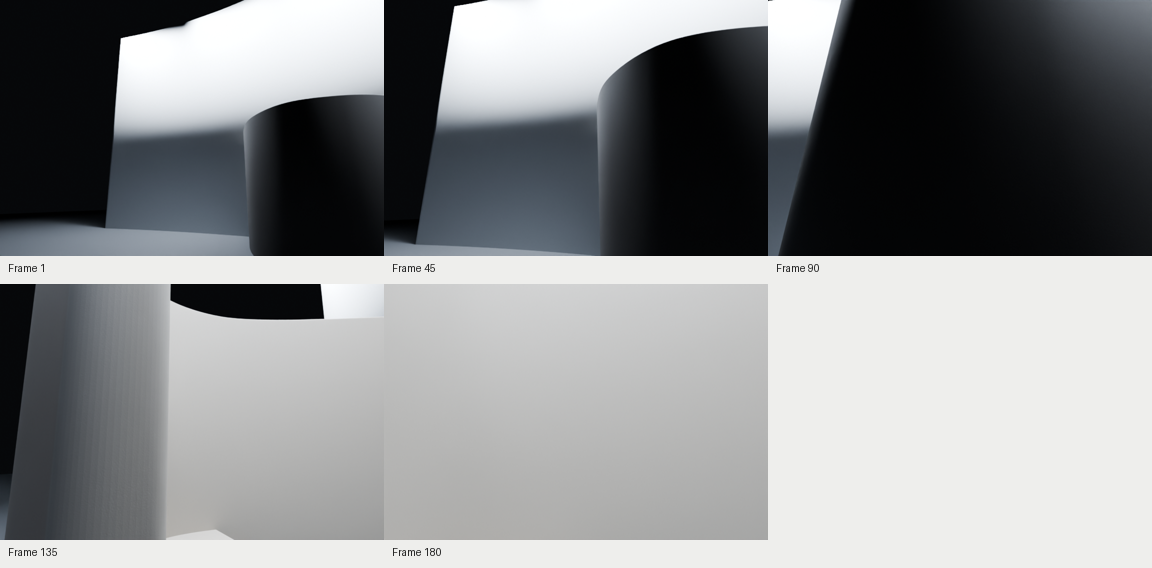


Evaluate: Evaluator is comparing actual image pixels with the fixed intention.

Design review: Design review completed; technical validity alone did not determine this judgment.


The sampled sequence communicates approach and obstruction more successfully than arrival. Increasing blade coverage and the surviving pale strip provide convincing evidence of physical interruption, supported by the measured static geometry. However, the opening begins too close to the obstruction, and the ending loses nearly every spatial cue needed for intimacy. The final blank surface cannot substitute for a sheltered pocket, visible ledge and continuing monumental wall. Revision should prioritize camera framing and clearance, then lighting separation, rather than additional geometry.

Scores / 5: intention preservation: 2; sequence readability: 2; transitions and pacing: 2; spatial composition: 2; visual legibility: 2

Preserved:
- The opening establishes a large pale surface against dark surroundings with some empty floor visible.
- Successive early samples clearly show increasing physical occlusion by a dark curved blade.
- A narrow glimpse of the pale wall survives the strongest sampled obstruction.
- Measurements support the specified 20-metre-long, 12-metre-high wall, four-metre blade, static scenery and fifteen-second timeline.

Transformed:
- The initially slender interruption becomes a substantial foreground mass from the opening frame.
- The narrow cool graze reads as broad bright illumination with a pronounced darker lower region.
- The intended sheltered encounter becomes an extreme surface close-up rather than a legible pocket.

Lost:
- A sufficiently complete opening upper silhouette and sustained exposed distance.
- Clear late-stage amber warmth, integ

One continuous, static scenography transforms an exposed encounter with a monumental wall into physical obstruction and then a sheltered, close-range encounter. The revised journey begins farther away, bends around the curled blade with generous clearance, and ends outside the pocket's open mouth, where its inner face, ledge, floor and continuing pale wall remain legible together.


Build: Designer is generating scene version 4.

Tool request: Build the continuous concave-wall passage, curled mineral blade and warm pocket with the prescribed fifteen-second camera journey.

Tool observation: Blender returned its execution result.
Tool status: ok

Inspect: Checking scene version 4 against technical requirements.

Technical checks: Independent measurements returned.
Technical checks: failed
Planned measurements matched: 3 / 4
- Plan measurement mismatch: Pocket_Ledge.dimensions; expected [2.0, 0.7, 0.42], observed [2.0, 0.9074938297271729, 0.41999998688697815], tolerance 0.08 m.

Technical repair: Technical repair 1/2; intention and plan stay fixed.
Plan measurement mismatch: Pocket_Ledge.dimensions; expected [2.0, 0.7, 0.42], observed [2.0, 0.9074938297271729, 0.41999998688697815], tolerance 0.08 m.

Build: Designer is generating scene version 5.

Tool request: Repair the ledge envelope to exactly 2.0 × 0.7 × 0.42 metres while preserving its curved embedded rear an

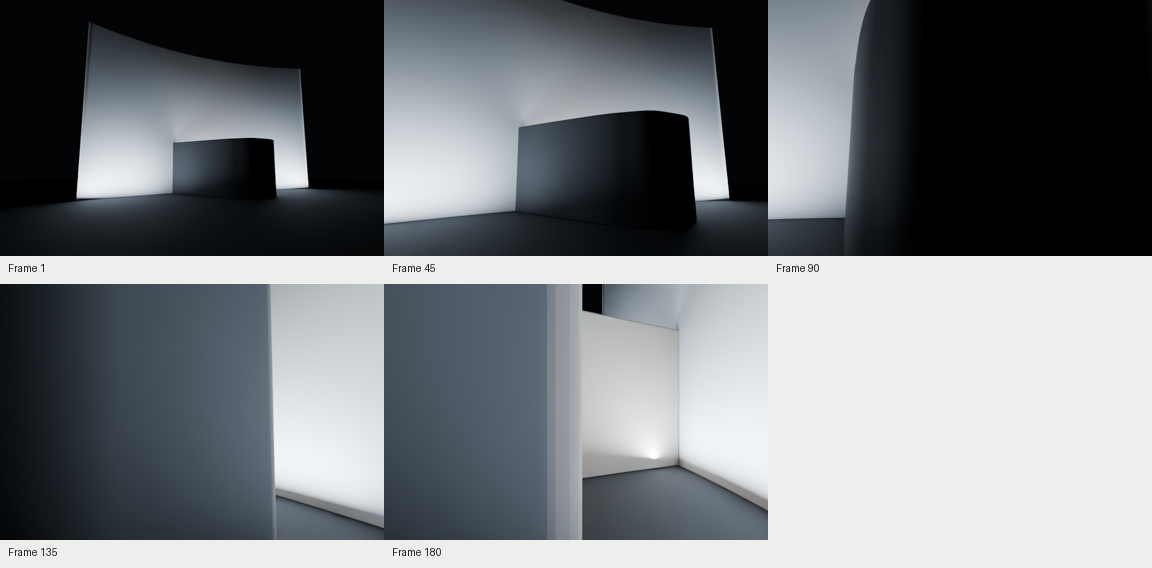


Evaluate: Evaluator is comparing actual image pixels with the fixed intention.

Design review: Design review completed; technical validity alone did not determine this judgment.


The opening convincingly establishes a monumental surface, and the middle samples deliver genuine interruption through increasing physical occlusion. The measured scale and static geometry support those readings without proving the complete journey. The decisive weakness is the destination: even at the final sample, the blade remains a foreground barrier, while the pocket, ledge, warmth, and tactile surface are not clearly communicated. Revision should prioritize earlier clearance and a legible sheltered final composition rather than additional geometry or decorative detail.

Scores / 5: intention preservation: 3; sequence readability: 3; transitions and pacing: 2; spatial composition: 3; visual legibility: 2

Preserved:
- Opening monumentality through a tall, continuous concave pale wall, visible upper silhouette, and exposed dark floor.
- Progressive physical occlusion by a dark blade while a glimpse of the original wall persists.
- Minimal static geometry and a consistent spatial setting; measured wall and blade heights match the intended scale.
- The measured frame range and playback rate support a fifteen-second run.

Transformed:
- The initially slender peripheral blade becomes an already substantial central object.
- The narrow cool grazing wash reads as broad wall illumination with localized bright lower areas.
- The final sheltered encounter reads more as a partially revealed angular recess behind a foreground barrier.

Lost:
- A clearly readable shallow curved pocket at the destination.
- The warm amber, textured close encounter and visibly integr

Watch the complete movement and pacing before judging the relation to the intention.
Remaining limitation: Design revision limit reached with unresolved feedback.


In [8]:
sequence_seven = ['monumentality', 'interruption', 'intimacy']
result_seven = await run_sequence(sequence_seven, "07_monumentality_interruption_intimacy")

## Study 8: instability → release → monumentality

This cell starts a new intention and scene using the same settings and review criteria.


Interpret: Interpreting instability → release → monumentality

Intention: The reference intention is now fixed.


Imagine a continuous passage beneath and beside a single ascending sweep of thick, curved mineral fins, ending in an open view of their collective mass. Use approximately fourteen fins, six to eighteen metres tall, arranged along a shallow crescent across a matte charcoal ground. Their rough, pale surfaces share one material; their changing spacing and alignment, rather than separate objects for each state, carry the journey.

During the first five seconds, the camera advances at eye level through the narrow end of the crescent. Nearby fins lean in alternating directions, overlap heavily, and conceal their upper edges beyond the frame. Uneven slits of cold light cross the ground; successive occlusions make the passage appear precarious, although every element remains motionless. A brighter opening is already visible between the distant fins.

Across the middle five seconds, the camera passes beyond the tight overlaps into progressively wider spacing. The fins gradually straighten while a broad wash of warm, low-angle light replaces the fragmented illumination. More ground and sky become visible, and the camera's forward pace gently eases.

In the final five seconds, the camera arcs outward and settles, revealing the crescent as a tall, coherent backdrop around an empty foreground. Broad illuminated faces alternate with deep shadowed edges. Its height and repeated vertical rhythm now dominate the small eye-level viewpoint. The opening remains visible at one end, preserving release within monumentality rather than closing the scene.


Plan: Planning design iteration 1.

Spatial plan: Spatial plan passed the handoff checks.


A continuous, stationary crescent of fourteen thick pale mineral fins rises from 6 to 18 metres. An eye-level camera begins beside the tightly overlapped, leaning end, follows its widening inner margin, then arcs into an empty charcoal foreground to reveal the ascending ensemble. Compression, release and monumentality come from one geometry rather than separate scenes.


Blender: Dedicated Blender session started.
Blender 5.1.2 | CYCLES | METAL GPU | metres

Build: Designer is generating scene version 1.

Tool request: Build the specified fourteen-fin mineral crescent with fixed cool and warm lighting and one continuous eye-level camera journey.

Tool observation: Blender returned its execution result.
Tool status: ok

Inspect: Checking scene version 1 against technical requirements.

Technical checks: Independent measurements returned.
Technical checks: passed
Planned measurements matched: 4 / 4

Preview: Rendering five ordered views of version 1.

Preview result: Preview render result.


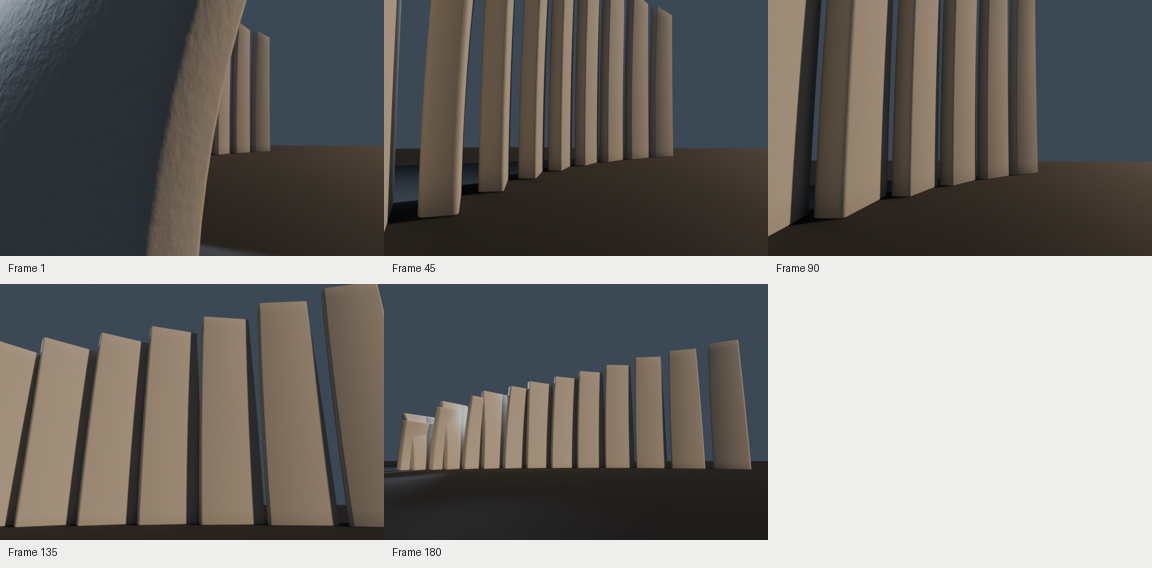


Evaluate: Evaluator is comparing actual image pixels with the fixed intention.

Design review: Design review completed; technical validity alone did not determine this judgment.


The renders communicate a coherent pale mineral family and a convincing final ascending mass, supported by the measured stationary geometry and eye-level camera. However, the intended emotional sequence is only partially visible. Early compression quickly becomes orderly repetition, the middle does not clearly expand, and the late close-up interrupts release before the final withdrawal. The strongest revision would be to camera routing, projected overlap and the continuity of one illuminated opening, rather than added geometry or decoration. Those changes would connect the existing successful final ensemble to the intended passage.

Scores / 5: intention preservation: 3; sequence readability: 3; transitions and pacing: 2; spatial composition: 3; visual legibility: 4

Preserved:
- Measurements establish fourteen stationary fins, six to eighteen metres tall, sharing one pale mineral material above a charcoal ground.
- Initial proximity and cropped upper edges communicate incomplete views and substantial scale.
- The final view unifies the ascending family above an empty foreground, with broad lit faces and shadowed edges.
- Sampled camera positions remain at approximately 1.65 metres.

Transformed:
- The passage reads primarily as movement beside an ordered screen rather than beneath and between competing inclinations.
- Release is expressed mainly by the final withdrawal, rather than a clearly expanding middle-stage opening.
- The shallow crescent and curved fins appear predominantly as a stepped sequence of slab-like faces.

Lost:
- Clearly alternating nearby leans and heavy multi-fin overlap throughout the initia

A continuous eye-level passage follows the concave side of fourteen stationary, curved mineral fins. Tight, alternating inclinations initially interrupt a persistent view toward a warm end opening. Increasing intervals and an earlier outward camera arc progressively expose ground, sky, and the complete ascending crescent. The final oblique view presents one coherent mineral mass around an empty foreground.


Build: Designer is generating scene version 2.

Tool request: Build the specified fourteen-fin crescent with shared mineral surfaces, static contrasting illumination, and a continuous eye-level camera arc.

Tool observation: Blender returned its execution result.
Tool status: ok

Inspect: Checking scene version 2 against technical requirements.

Technical checks: Independent measurements returned.
Technical checks: passed
Planned measurements matched: 4 / 4

Preview: Rendering five ordered views of version 2.

Preview result: Preview render result.


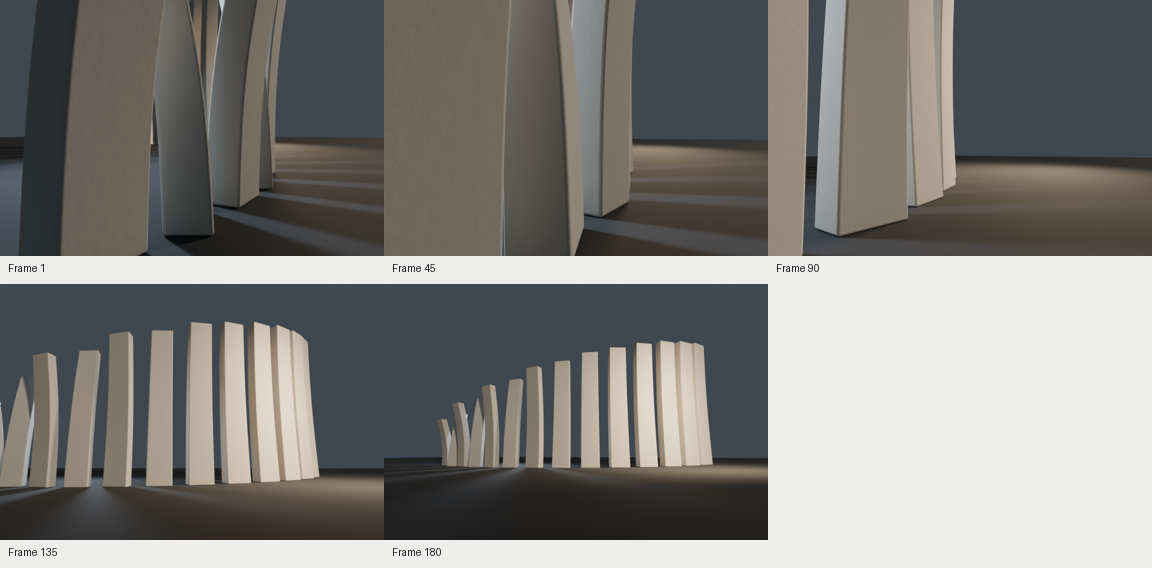


Evaluate: Evaluator is comparing actual image pixels with the fixed intention.

Design review: Design review completed; technical validity alone did not determine this judgment.


The sampled sequence convincingly progresses from close, cropped mineral surfaces to a legible ascending ensemble across empty ground. Material continuity, initial overlap, and the final vertical rhythm are clear strengths, supported by the measured stationary geometry and eye-level camera. However, the central release mechanism is weakened: openness appears beside the fins rather than as a persistent gap expanding through them. The final view also flattens the crescent and compresses its tallest end. Targeted camera and lighting revisions would strengthen the intended journey without adding geometry.

Scores / 5: intention preservation: 3; sequence readability: 4; transitions and pacing: 3; spatial composition: 4; visual legibility: 4

Preserved:
- A consistent pale, visibly textured mineral family on dark matte ground.
- Initial overhead cropping, overlap, and competing inclinations communicate partial, uncertain views.
- Increasing open ground and sky lead to a collective final silhouette.
- Measurements confirm fourteen stationary fins approximately six to eighteen metres tall and an eye-level camera at the sampled poses.
- The final composition retains empty foreground and an ascending vertical rhythm.

Transformed:
- The passage reads predominantly as travel beside a row rather than beneath and through a crescent.
- Release is carried more by shifting the fins leftward and withdrawing than by visibly expanding successive intervals.
- The final crescent reads as an ascending screen, with the tallest end visually compressed.

Lost:
- A clearly identifiable bright gap anticipated 

A continuous, stationary crescent of fourteen thick pale mineral fins rises from 6 to 18 metres above matte charcoal ground. A single eye-level camera journey begins inside the low, tightly overlapping end, follows a specific illuminated inter-fin opening into widening intervals, then arcs outward to reveal the entire ascending ensemble. Camera alignment and oblique lighting address the previous feedback without adding separate environments or state-specific geometry.


Build: Designer is generating scene version 3.

Tool request: Build the stationary ascending mineral crescent, fixed cool-to-warm lighting, and continuous eye-level camera journey.

Tool observation: Blender returned its execution result.
Tool status: ok

Inspect: Checking scene version 3 against technical requirements.

Technical checks: Independent measurements returned.
Technical checks: passed
Planned measurements matched: 5 / 5

Preview: Rendering five ordered views of version 3.

Preview result: Preview render result.


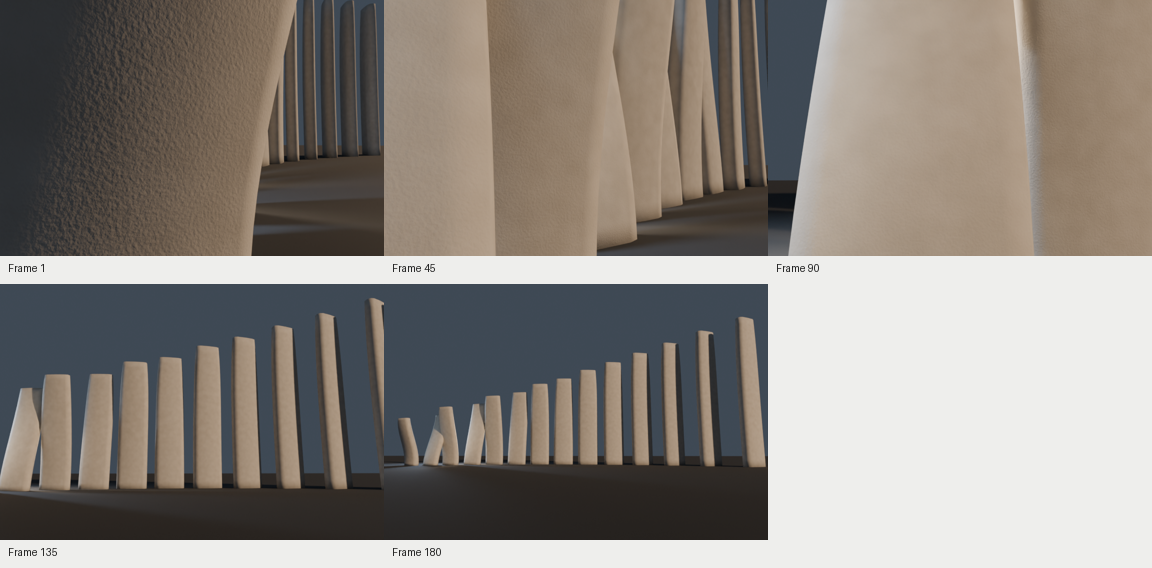


Evaluate: Evaluator is comparing actual image pixels with the fixed intention.

Design review: Design review completed; technical validity alone did not determine this judgment.


The sampled views communicate close mineral obstruction followed by a coherent ascending ensemble, and the final composition successfully combines repeated vertical mass with empty ground. Measurements support the intended stationary family, shared material, dimensions, and eye-level viewpoint. However, the middle sample contradicts progressive release: visibility contracts before the later reveal. The persistent bright opening and cool-to-warm transition are also weak. Revision should prioritize sightline continuity and the timing of clearance, preserving the successful final rhythm rather than adding geometry or decorative complexity.

Scores / 5: intention preservation: 3; sequence readability: 3; transitions and pacing: 2; spatial composition: 4; visual legibility: 4

Preserved:
- Fourteen stationary fins with one shared mineral material and measured heights of six to eighteen metres.
- Initial close occlusion, cropped upper edges, and visible mineral roughness.
- Final ascending collective silhouette, repeated illuminated faces, dark edges, and empty foreground.
- Measured camera height of 1.65 metres at the supplied poses.

Transformed:
- Passage through competing inclinations reads primarily as movement beside a closely overlapping wall.
- Progressive middle release becomes a delayed reveal after a strongly obstructed midpoint.
- The shallow crescent reads predominantly as a frontal ascending row.

Lost:
- A clearly identifiable bright gap that persists from initial compression into final release.
- Increasing visible ground and sky during the sampled middle phase.
- A strong temporal distinction between fragmen

Watch the complete movement and pacing before judging the relation to the intention.
Remaining limitation: Design revision limit reached with unresolved feedback.


In [9]:
sequence_eight = ['instability', 'release', 'monumentality']
result_eight = await run_sequence(sequence_eight, "08_instability_release_monumentality")